# Supervised learning: how a model learns

<p class="nb-download">Run it yourself. First time: <a href="_static/geoai_hexagons.zip" download>the zip with all notebooks, the helpers and the data</a>. Already have that folder: <a href="_static/notebooks/supervised.ipynb" download>this notebook</a>.</p>

<div class="slides n2"><a href="_static/slides/split.png"><img src="_static/slides/split.png" alt="Lecture slide: Training, validation, test: one table, three parts"></a><a href="_static/slides/ways_part1.png"><img src="_static/slides/ways_part1.png" alt="Lecture slide: From training data to test data: the two paradigms of part 1"></a></div>
<p class="slides-caption">From the lecture <a href="https://introsda.readthedocs.io/en/latest/lessons/L10/intro-to-GeoAI-2.html">Introduction to GeoAI, part 2</a>. Click a slide to enlarge it.</p>

```{admonition} Question
:class: tip
How well does a fitted model predict hexagons it has not seen?
```

**In this notebook:** 1 · two tasks  2 · a line  3 · training  4 · a decision boundary  5 · unseen hexagons  6 · flexibility

## 1 · Two tasks

**Supervised learning** fits a rule to rows whose answer is known. The answer is a category (**classification**) or a number (**regression**).

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier

import helpers as h

hexes, X, y, W = h.load()        # the table, the features, the labels, the neighbours
SEED = 0

Our table holds one answer of each kind. The numbers 1 to 5 mark the five hexagons of [the data page](data).

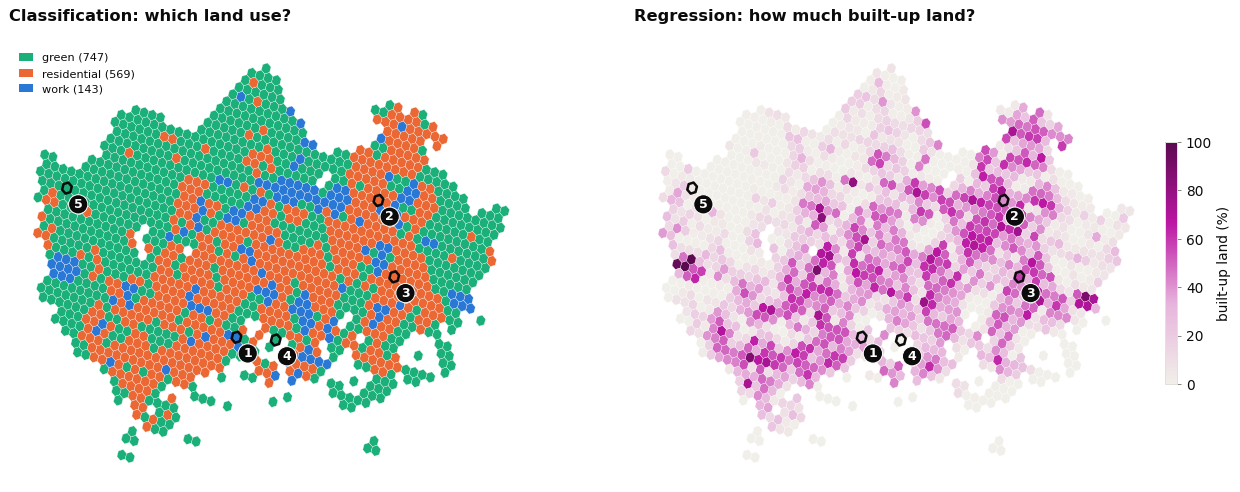

In [2]:
five = h.five(hexes)             # place name -> row number
built_up_pct = ((hexes["share_residential"] + hexes["share_work"]) * 100).to_numpy()
h.plot_two_tasks(hexes, y, built_up_pct, five.values);

## 2 · A line with two parameters

Regression first. Do hexagons with more points of interest have more built-up land? The horizontal axis is logarithmic, because a few hexagons hold hundreds of points of interest and most a handful.

median share of built-up land (%), by the number of points of interest in the hexagon
none              0.0
1 to 10           6.0
11 to 50         29.0
51 to 200        42.0
more than 200    39.0


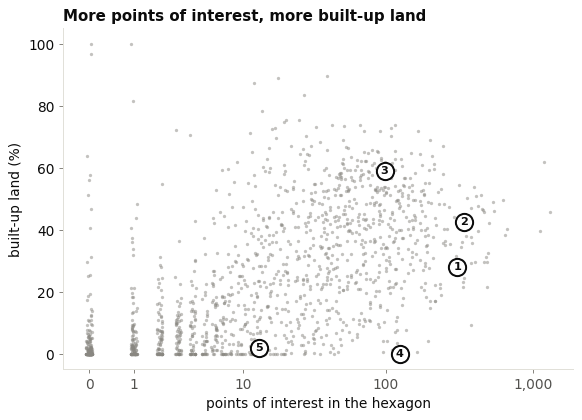

In [3]:
poi_total = hexes["poi_total"].to_numpy(float)
poi_log = np.log10(1 + poi_total).reshape(-1, 1)        # x: the values 0, 1, 2, 3 stand for 0, 9, 99 and 999 points of interest
bands = pd.cut(pd.Series(poi_total), [-1, 0, 10, 50, 200, 5000], labels=["none", "1 to 10", "11 to 50", "51 to 200", "more than 200"])
by_band = pd.Series(built_up_pct).groupby(bands, observed=True).median().round(0)
print("median share of built-up land (%), by the number of points of interest in the hexagon")
print(by_band.to_string())
h.plot_poi_line(poi_log, built_up_pct, five.values);

**Result.** Without points of interest the typical hexagon has no built-up land. With 51 to 200 it has 42%.

The simplest rule that returns a number for any hexagon is a line, *y = a + b × x*. Its **parameters** are a and b. Its **error** is the typical distance from the points (root mean square). Three choices on made-up points:

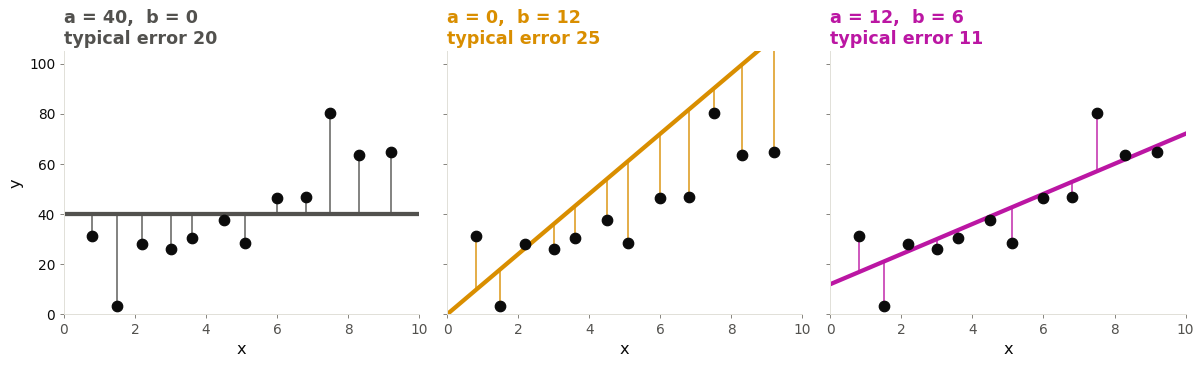

In [4]:
toy_x = np.array([0.8, 1.5, 2.2, 3.0, 3.6, 4.5, 5.1, 6.0, 6.8, 7.5, 8.3, 9.2])          # made-up points, for this picture only
toy_y = 12 + 6 * toy_x + np.random.default_rng(3).normal(0, 7, len(toy_x))
choices = [(40, 0), (0, 12), (12, 6)]          # a and b of three lines
h.plot_toy_lines(toy_x, toy_y, choices);

In [5]:
toy_error = lambda a, b: float(np.sqrt(((a + b * toy_x - toy_y) ** 2).mean()))
h.note("toy_points", {"x": [round(float(v), 2) for v in toy_x], "y": [round(float(v), 1) for v in toy_y]})
h.note("toy_line", [{"a": a, "b": b, "error": round(toy_error(a, b))} for a, b in choices])

**Try it.** Move a and b. Can you get the typical error below 11?

<div class="linelab"></div>

On the hexagons, `LinearRegression` returns the a and b with the smallest error.

In [6]:
line = LinearRegression().fit(poi_log, built_up_pct)
a_fit, b_fit = float(line.intercept_), float(line.coef_[0])
new_row = int(round(a_fit + b_fit * np.log10(1 + 50)))


def typical_error(a, b):
    """How far a line lies from the hexagons: the root of the mean squared error, in points of built-up share."""
    return float(np.sqrt(((a + b * poi_log.ravel() - built_up_pct) ** 2).mean()))


print(f"y = {a_fit:.1f} + {b_fit:.1f} x, with x = log10(1 + number of POIs) and y = built-up land (%)       R2 = {line.score(poi_log, built_up_pct):.2f}")
print(f"typical error: {typical_error(built_up_pct.mean(), 0):.0f} points with a flat line at the average, {typical_error(a_fit, b_fit):.0f} with the fitted line")
print(f"a new hexagon with 50 points of interest: the line answers {new_row}% built-up land")

y = 2.7 + 17.8 x, with x = log10(1 + number of POIs) and y = built-up land (%)       R2 = 0.38
typical error: 21 points with a flat line at the average, 17 with the fitted line
a new hexagon with 50 points of interest: the line answers 33% built-up land


What the line says for the five hexagons:

In [7]:
line_rows = pd.DataFrame({"place": list(five.index), "points of interest": poi_total[five.values].astype(int),
                          "built-up land (%)": built_up_pct[five.values].round(0).astype(int),
                          "the line says (%)": line.predict(poi_log[five.values]).round(0).astype(int)}, index=range(1, 6))
line_rows["error"] = line_rows["the line says (%)"] - line_rows["built-up land (%)"]
line_rows

,place,points of interest,built-up land (%),the line says (%),error
1,Otaniemi,305,28,47,19
2,Tikkurila,338,42,48,6
3,Kontula,98,59,38,-21
4,Seurasaari,124,0,40,40
5,Nuuksio,13,2,23,21


In [8]:
h.note("bands", {k: int(v) for k, v in by_band.items()})
h.note("line", {"a": round(a_fit, 1), "b": round(b_fit, 1), "r2": round(float(line.score(poi_log, built_up_pct)), 2),
                "error_zero": round(typical_error(0, 0)), "error_flat": round(typical_error(built_up_pct.mean(), 0)),
                "error_fit": round(typical_error(a_fit, b_fit)), "mean": round(float(built_up_pct.mean())), "new_row_50": new_row,
                "rows": line_rows.reset_index(drop=True).to_dict("records")})

**Result.** The typical error is 17 points. **R²** is 0.38: the line accounts for 38% of the differences between hexagons. For Seurasaari, an island without built-up land, it is 40 points too high.

## 3 · Training

We chose the form of the rule. The computer finds a and b: start at 0, measure the error, change both numbers a little in the direction that reduces it, repeat. This is **training** (here by gradient descent).

In [9]:
def fitting_path(x, t, shown=(0, 1, 2, 4, 8, 16, 32, 300), rate=0.2):
    """Fit t = a + b * x step by step, and return a and b after the steps listed in `shown`."""
    z = (x - x.mean()) / x.std()                     # the same x on a scale that makes the steps even
    a, b, path = 0.0, 0.0, {}
    for step in range(max(shown) + 1):
        if step in shown:
            path[step] = (a - b * x.mean() / x.std(), b / x.std())        # back on the original scale
        off = a + b * z - t
        a, b = a - rate * off.mean(), b - rate * (off * z).mean()
    return path

step   0: a =   0.0, b =  0.0, typical error 31.9 points
step   1: a =   0.5, b =  3.6, typical error 27.4 points
step   2: a =   1.0, b =  6.4, typical error 24.2 points
step   4: a =   1.6, b = 10.5, typical error 20.2 points
step   8: a =   2.3, b = 14.8, typical error 17.5 points
step  16: a =   2.6, b = 17.3, typical error 17.0 points
step  32: a =   2.7, b = 17.8, typical error 16.9 points
step 300: a =   2.7, b = 17.8, typical error 16.9 points


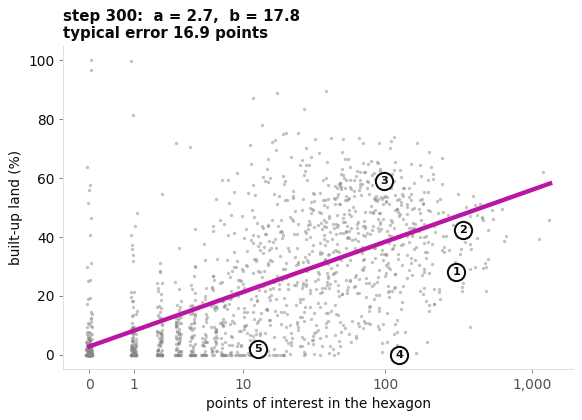

In [10]:
path = fitting_path(poi_log.ravel(), built_up_pct)
for step, (a, b) in path.items():
    print(f"step {step:3d}: a = {a:5.1f}, b = {b:4.1f}, typical error {typical_error(a, b):4.1f} points")
h.plot_poi_line(poi_log, built_up_pct, five.values, *path[300], title="step 300");

In [11]:
h.note("training", {"error_start": round(typical_error(*path[0]), 1), "error_end": round(typical_error(*path[300]), 1), "steps": 300})
if h.SAVE:    # the slider of the website
    h.frames(lambda step: h.plot_poi_line(poi_log, built_up_pct, five.values, *path[step], title=f"step {step}"), list(path), "training")

<div class="frames" data-name="training" data-labels="step 0|step 1|step 2|step 4|step 8|step 16|step 32|step 300"></div>

**Result.** After 32 steps a and b stay at 2.7 and 17.8, the values of step 2. The fitted line is the **model**.

## 4 · A decision boundary

Classification now. With two of the 16 counts as axes, every hexagon is a dot in **feature space**. Which pair separates the three land uses best? Fit a rule on each of the 120 pairs.

In [12]:
FEATURES = h.FEATURES
pairs = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        rule = LogisticRegression(max_iter=2000).fit(X[:, [i, j]], y)
        pairs.append({"count 1": FEATURES[i], "count 2": FEATURES[j], "right": rule.score(X[:, [i, j]], y)})
pairs = pd.DataFrame(pairs).sort_values("right", ascending=False).reset_index(drop=True)
print(f"{len(pairs)} pairs of counts: best {pairs['right'].max():.0%}, median {pairs['right'].median():.0%}, worst {pairs['right'].min():.0%}")
print(pairs.head(5).round(3).to_string())

120 pairs of counts: best 75%, median 70%, worst 56%
      count 1         count 2  right
0  shop_daily       education  0.751
1         car            play  0.751
2   education             car  0.751
3         car         lodging  0.748
4         car  craft_industry  0.748


**Result.** No pair gets more than 75% of the hexagons right. We take the second: `car` (parking and fuel) and `play` (playgrounds and picnic sites).

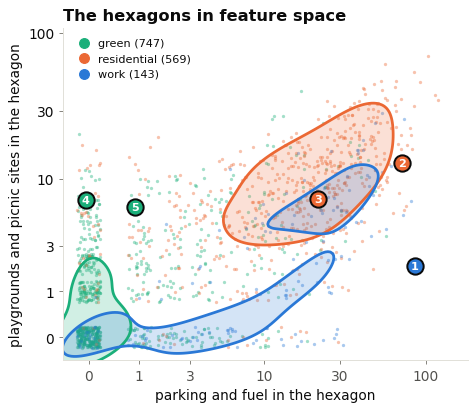

In [13]:
two = [FEATURES.index("car"), FEATURES.index("play")]
names2 = ["parking and fuel in the hexagon", "playgrounds and picnic sites in the hexagon"]
h.feature_plane(X[:, two], y, names2, rows=five.values, title="The hexagons in feature space");

Each shaded region holds the densest half of one land use. The regions overlap. **Logistic regression** is the line of step 2 for categories: its parameters place straight **decision boundaries** between the land uses.

hexagons on the right side of the boundaries: 75%     always answering 'green': 51%
parameters that place the boundaries: 9
share of each land use that the rule on two counts finds: green 85%, residential 76%, work 19%


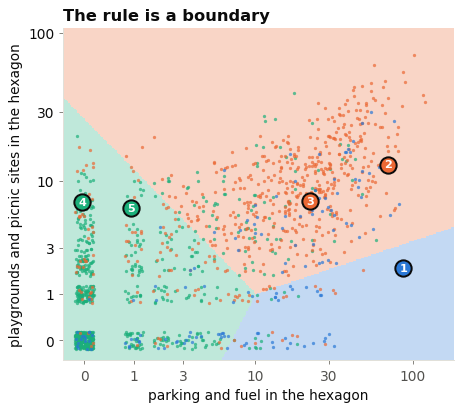

In [14]:
boundary = LogisticRegression(max_iter=2000).fit(X[:, two], y)
answers = boundary.predict(X[:, two])
found = {c: float((answers[y == c] == c).mean()) for c in h.CLASSES}
print(f"hexagons on the right side of the boundaries: {boundary.score(X[:, two], y):.0%}     always answering 'green': {(y == 'green').mean():.0%}")
print(f"parameters that place the boundaries: {boundary.coef_.size + boundary.intercept_.size}")
print("share of each land use that the rule on two counts finds: " + ", ".join(f"{c} {v:.0%}" for c, v in found.items()))
h.regions(boundary, X[:, two], y, names2, title="The rule is a boundary", rows=five.values, counts=(0, 1, 3, 10, 30, 100));

The background colour is the answer of the rule. The same answers on the map:

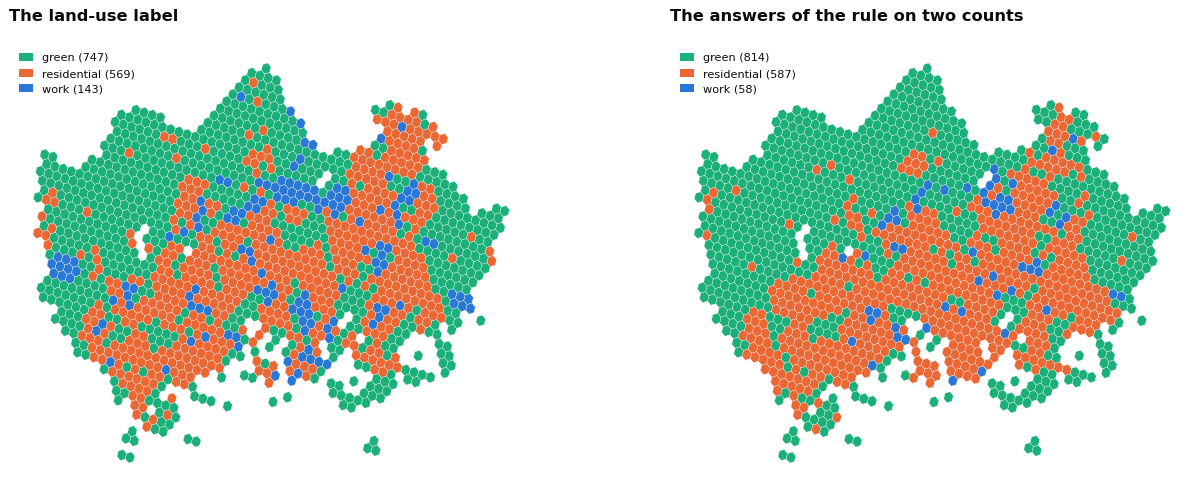

In [15]:
h.plot_rule_maps(hexes, y, answers);

**Result.** 75% right, against 51% for always answering `green`. The rule finds 19% of the work hexagons. Two counts cannot tell work from residential.

The same kind of rule with all 16 counts:

In [16]:
all_counts = LogisticRegression(max_iter=3000).fit(X, y)
print(f"hexagons on the right side of the boundaries, with all 16 counts: {all_counts.score(X, y):.0%}")

hexagons on the right side of the boundaries, with all 16 counts: 79%


In [17]:
rank = int(pairs.index[(pairs["count 1"] == "car") & (pairs["count 2"] == "play")][0]) + 1
h.note("pairs", {"n": len(pairs), "best": round(float(pairs['right'].max()), 3), "median": round(float(pairs['right'].median()), 3),
                 "rank_car_play": rank, "best_pair": [pairs.loc[0, "count 1"], pairs.loc[0, "count 2"]]})
h.note("boundary", {"two": round(float(boundary.score(X[:, two], y)), 3), "sixteen": round(float(all_counts.score(X, y)), 3),
                    "green": round(float((y == 'green').mean()), 3), "parameters": int(boundary.coef_.size + boundary.intercept_.size),
                    "found": {c: round(v, 2) for c, v in found.items()}})

## 5 · Unseen hexagons

These 79% were scored on the rows the rule was fitted to, which flatters a model. So the hexagons are dealt at random into three piles before any learning:

- **Training** (60%) · fits the parameters.
- **Validation** (20%) · chooses between versions of the model.
- **Test** (20%) · looked at once, at the end: the unseen hexagons.

training 875, validation 292, test 292
99% of the test hexagons touch at least one training hexagon.


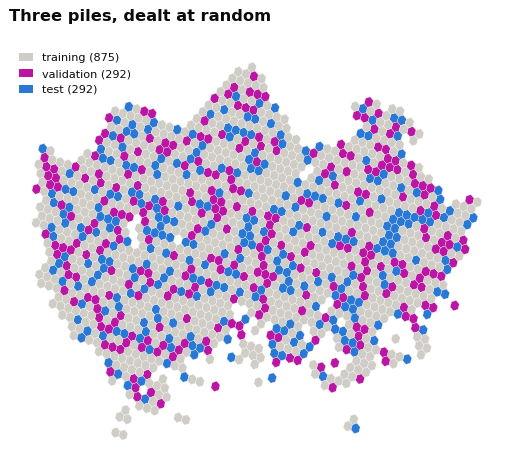

In [18]:
p_train, p_valid, p_test = h.three_piles(y, SEED)
touching = np.mean([np.isin(W[i].indices, p_train).any() for i in p_test])
print(f"training {len(p_train)}, validation {len(p_valid)}, test {len(p_test)}")
print(f"{touching:.0%} of the test hexagons touch at least one training hexagon.")
h.plot_three_piles(hexes, p_valid, p_test);

The piles are mixed all over the map. The page on [challenges](challenges) comes back to this.

Two models, 20 deals each: the rule with all 16 counts, and a memoriser, a decision tree that splits until it cannot separate its training rows further.

In [19]:
scores = []
for seed in range(20):
    tr, va, te = h.three_piles(y, seed)
    memoriser = DecisionTreeClassifier(random_state=0).fit(X[tr], y[tr])
    rule = LogisticRegression(max_iter=3000).fit(X[tr], y[tr])
    scores.append({"memoriser, seen": memoriser.score(X[tr], y[tr]), "memoriser, unseen": memoriser.score(X[te], y[te]),
                   "rule, seen": rule.score(X[tr], y[tr]), "rule, unseen": rule.score(X[te], y[te])})
scores = pd.DataFrame(scores).mean()
print("share of hexagons answered correctly (means of 20 deals)")
print(scores.map("{:.0%}".format).to_string())
print(f"always answering 'green': {(y == 'green').mean():.0%}")

share of hexagons answered correctly (means of 20 deals)
memoriser, seen      97%
memoriser, unseen    72%
rule, seen           80%
rule, unseen         79%
always answering 'green': 51%


In [20]:
h.note("unseen", {k: round(float(v), 3) for k, v in scores.items()})
h.note("piles", {"training": len(p_train), "validation": len(p_valid), "test": len(p_test), "touching": round(float(touching), 2)})

**Result.** The rule gets 79% of the unseen hexagons right, against 51% for always answering `green`. The memoriser scores 97% on its own rows and 72% on unseen ones. A score on the training rows shows how well a model remembers.

## 6 · Flexibility

A **hyperparameter** is a setting we choose before training, here the degree of a polynomial: 0 is a flat line, 1 a straight line, 6 a curve. Each is fitted to 30 training hexagons only.

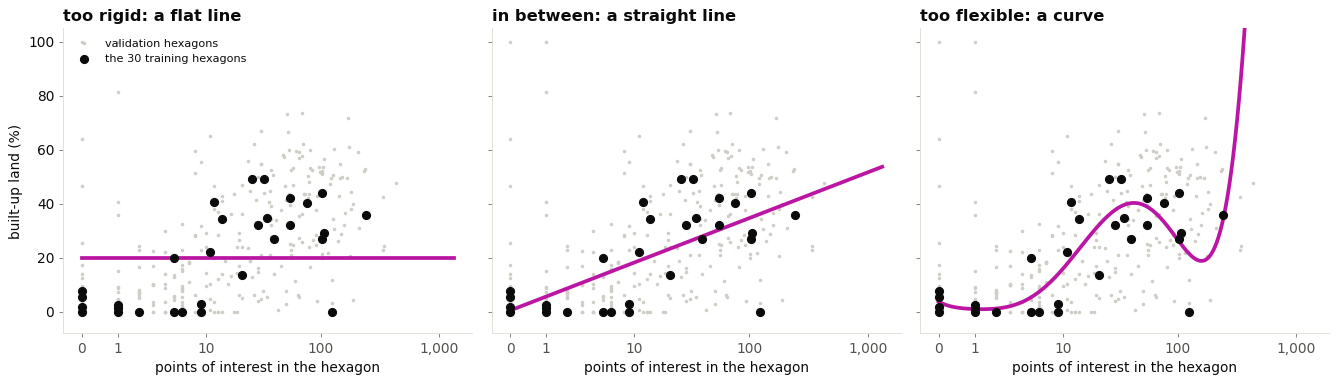

In [21]:
def curve(degree):
    """A polynomial of the given degree: 0 is a flat line, 1 a straight line, 6 a curve that may bend five times."""
    return make_pipeline(MinMaxScaler(), PolynomialFeatures(degree), LinearRegression())


few = np.random.default_rng(SEED).choice(p_train, 30, replace=False)       # 30 hexagons of the training pile
h.plot_flexibility(curve, poi_log, built_up_pct, few, p_valid);

Which degree is best? 200 deals, each with its own 30 training hexagons, scored by R² on those 30 and on the validation pile.

In [22]:
DEGREES = [0, 1, 2, 3, 6, 9]
runs = []
for seed in range(200):
    tr, va, te = h.three_piles(y, seed)
    few_tr = np.random.default_rng(seed).choice(tr, 30, replace=False)
    for degree in DEGREES:
        m = curve(degree).fit(poi_log[few_tr], built_up_pct[few_tr])
        runs.append({"seed": seed, "degree": degree, "training": m.score(poi_log[few_tr], built_up_pct[few_tr]),
                     "validation": m.score(poi_log[va], built_up_pct[va]), "test": m.score(poi_log[te], built_up_pct[te])})
runs = pd.DataFrame(runs)
medians = runs.groupby("degree")[["training", "validation"]].median()
print("R2, median of 200 deals (30 training hexagons each)\n" + medians.round(2).to_string())

R2, median of 200 deals (30 training hexagons each)
        training  validation
degree                      
0           0.00       -0.02
1           0.40        0.35
2           0.43        0.33
3           0.47        0.33
6           0.53       -0.04
9           0.59     -103.37


In [23]:
if h.SAVE:    # the slider of the website
    h.frames(lambda degree: h.plot_flexibility_frame(degree, curve, poi_log, built_up_pct, few, p_valid, medians), DEGREES, "flexibility")

<div class="frames" data-name="flexibility" data-labels="a flat line|a straight line|may bend once|may bend twice|may bend 5 times|may bend 8 times"></div>

**Result.** On its own 30 hexagons the most flexible rule wins (0.59 for degree 9). On the validation pile the straight line wins (0.35) and degree 6 falls below 0. The flat line is too rigid (**underfitting**), the curve too flexible (**overfitting**).

So the validation pile chooses the degree, and the test pile is looked at once.

In [24]:
chosen = runs.loc[runs.groupby("seed")["validation"].idxmax()]
gentle = int((chosen["degree"] <= 3).sum())
print(f"The degree that does best on validation is 1, 2 or 3 in {gentle} of 200 deals.")
print(f"The chosen rule: R2 {chosen['validation'].median():.2f} on the validation pile, {chosen['test'].median():.2f} on the test pile (medians).")
big = curve(6).fit(poi_log[p_train], built_up_pct[p_train])
big_line = curve(1).fit(poi_log[p_train], built_up_pct[p_train])
print(f"With all {len(p_train)} training hexagons the same curve of degree 6 reaches {big.score(poi_log[p_valid], built_up_pct[p_valid]):.2f} on validation, "
      f"the straight line {big_line.score(poi_log[p_valid], built_up_pct[p_valid]):.2f}.")

The degree that does best on validation is 1, 2 or 3 in 194 of 200 deals.
The chosen rule: R2 0.36 on the validation pile, 0.34 on the test pile (medians).
With all 875 training hexagons the same curve of degree 6 reaches 0.31 on validation, the straight line 0.29.


In [25]:
h.note("flexibility", {"training": {int(d): round(float(v), 2) for d, v in medians["training"].items()},
                       "validation": {int(d): round(float(v), 2) for d, v in medians["validation"].items()},
                       "gentle_of_200": gentle, "chosen_validation": round(float(chosen["validation"].median()), 2),
                       "chosen_test": round(float(chosen["test"].median()), 2),
                       "all_rows_curve": round(float(big.score(poi_log[p_valid], built_up_pct[p_valid])), 2),
                       "all_rows_line": round(float(big_line.score(poi_log[p_valid], built_up_pct[p_valid])), 2)})

**Result.** Validation picks degree 1, 2 or 3 in 194 of 200 deals. R² is 0.36 on validation and 0.34 on test: a rule looks a little better on the pile that chose it. Flexibility hurts when rows are few: with all 875 training hexagons the curve does no harm.

**Next:** [semi-supervised learning](semi_supervised)